# ShopStream at Scale — Distributed Batch Analytics with PySpark

**Как запускать:** `Run All` в VS Code, или из терминала `python run_a2.py --scale medium --seed <ID4>`.
Все таблицы и графики сохраняются в папку `results/`.

Части: **A** ингест и хранение · **B** качество данных · **C** аналитика · **D** joins и skew · **E** бенчмарки · **F** отчёт

## 0. Параметры и данные

In [1]:
import os, sys, subprocess

# scale и seed можно передать снаружи (это делает run_a2.py); иначе берутся значения по умолчанию
SCALE = os.environ.get("A2_SCALE", "small")        # разработка: small, финальные цифры: medium
SEED  = int(os.environ.get("A2_SEED", "5820"))     # <-- ЗАМЕНИ 1234 на последние 4 цифры студенческого

DATA    = f"data/shopstream_{SCALE}_{SEED}"
EVENTS  = f"{DATA}/events"
RESULTS = "results"
os.makedirs(RESULTS, exist_ok=True)
print(SCALE, SEED, DATA)

medium 5820 data/shopstream_medium_5820


In [2]:
# Генерируем данные, только если их ещё нет (тот же seed -> точно такие же данные)
if not os.path.exists(f"{DATA}/_meta.json"):
    subprocess.run([sys.executable, "shopstream_gen.py", "--out", DATA,
                    "--scale", SCALE, "--seed", str(SEED)], check=True)
print(open(f"{DATA}/_meta.json").read())

{
  "scale": "medium",
  "seed": 5820,
  "n_users": 30000,
  "n_products": 5000,
  "n_days": 60,
  "n_events_written": 2828711,
  "n_files": 240,
  "start_date": "2026-07-01"
}


In [3]:
import os, sys, shutil
print("Python:", sys.executable)
print("JAVA_HOME:", os.environ.get("JAVA_HOME"))
print("java в PATH:", shutil.which("java"))
print("java в conda-окружении:", os.path.exists(os.path.join(sys.prefix, "Library", "bin", "java.exe")))

Python: C:\Users\Dana\miniconda3\envs\shopstream\python.exe
JAVA_HOME: C:\Users\Dana\miniconda3\envs\shopstream\Library\lib\jvm
java в PATH: C:\Users\Dana\miniconda3\envs\shopstream\Library\bin\java.EXE
java в conda-окружении: True


## 1. Spark и окружение

In [4]:
import time, statistics, platform, json
import pandas as pd
import psutil

# Spark должен использовать тот же Python, что и ноутбук
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

if platform.system() == "Windows":
    # Java из conda-окружения: VS Code не активирует conda, поэтому указываем путь сами
    conda_java = os.path.join(sys.prefix, "Library")
    if os.path.exists(os.path.join(conda_java, "bin", "java.exe")):
        os.environ["JAVA_HOME"] = conda_java
        os.environ["PATH"] = os.path.join(conda_java, "bin") + ";" + os.environ["PATH"]
    # winutils для записи файлов
    os.environ["HADOOP_HOME"] = r"C:\hadoop"
    os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]

print("JAVA_HOME =", os.environ.get("JAVA_HOME"))

from pyspark.sql import SparkSession, functions as F, types as T

RAM_GB = psutil.virtual_memory().total / 1e9

spark = (SparkSession.builder
         .master("local[*]")
         .appName("ShopStream-A2")
         .config("spark.driver.memory", f"{max(2, int(RAM_GB * 0.5))}g")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.local.dir", os.path.abspath("spark_tmp"))
         .config("spark.ui.port", "4040")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")

print("Spark", spark.version, "| ядер:", spark.sparkContext.defaultParallelism)
print("Spark UI: http://localhost:4040")

JAVA_HOME = C:\Users\Dana\miniconda3\envs\shopstream\Library


Spark 3.5.3 | ядер: 16
Spark UI: http://localhost:4040


In [5]:
# Окружение — обязательно для отчёта (все замеры без него не засчитываются)
java_out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
ENV = {
    "OS": platform.platform(),
    "CPU": platform.processor(),
    "CPU cores (logical)": os.cpu_count(),
    "RAM_GB": round(RAM_GB, 1),
    "Python": sys.version.split()[0],
    "Java": next(l for l in java_out.splitlines() if "version" in l).strip(),
    "Spark": spark.version,
    "scale": SCALE, "seed": SEED,
}
json.dump(ENV, open(f"{RESULTS}/environment.json", "w"), indent=2)
ENV

{'OS': 'Windows-10-10.0.26200-SP0',
 'CPU': 'AMD64 Family 26 Model 96 Stepping 0, AuthenticAMD',
 'CPU cores (logical)': 16,
 'RAM_GB': 16.2,
 'Python': '3.11.17',
 'Java': 'openjdk version "17.0.18" 2026-01-20 LTS',
 'Spark': '3.5.3',
 'scale': 'medium',
 'seed': 5820}

## 2. Инструменты для замеров
- `bench` — медиана из 3 запусков + 1 прогревочный (не учитывается).
- `force` — заставляет Spark посчитать весь DataFrame, но ничего не сохранять (`noop`).
  `.show()` считает только 20 строк, `.collect()` меряет перенос данных в драйвер — оба врут.

In [6]:
def bench(fn, runs=3, warmup=True):
    """Запускает fn() runs раз. Возвращает (медиана, список времён) в секундах."""
    if warmup:
        fn()                           # прогрев: кэш диска ОС, загрузка классов Java
    times = []
    for _ in range(runs):
        spark.catalog.clearCache()     # чистим кэш Spark между запусками
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return statistics.median(times), times


def force(df):
    """Полностью вычисляет df, ничего не записывая на диск."""
    df.write.format("noop").mode("overwrite").save()

# Part A — Ingestion and storage layout
## A1. Чтение схемы: автоопределение vs явная схема

In [7]:
# Первый взгляд на сырые события
peek = spark.read.json(EVENTS)
peek.printSchema()
peek.show(5, truncate=False)

root
 |-- app_version: string (nullable = true)
 |-- device: string (nullable = true)
 |-- event_id: string (nullable = true)
 |-- event_ts: string (nullable = true)
 |-- event_type: string (nullable = true)
 |-- ingest_ts: string (nullable = true)
 |-- price: double (nullable = true)
 |-- product_id: string (nullable = true)
 |-- quantity: long (nullable = true)
 |-- session_id: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- date: date (nullable = true)



+-----------+------+------------------+--------------------+-----------+--------------------+-----+----------+--------+----------+--------+----------+
|app_version|device|event_id          |event_ts            |event_type |ingest_ts           |price|product_id|quantity|session_id|user_id |date      |
+-----------+------+------------------+--------------------+-----------+--------------------+-----+----------+--------+----------+--------+----------+
|6.0.0      |mobile|e_2f7586c9823c65f3|2026-07-12T13:02:39Z|view       |2026-07-12T13:02:39Z|65.05|p_01970   |1       |s_0001c8e7|u_007769|2026-07-12|
|5.4.0      |tablet|e_694a16318ffb9bed|2026-07-12T13:02:39Z|view       |2026-07-12T13:02:39Z|61.48|p_01970   |1       |s_0005cfda|u_025272|2026-07-12|
|5.3.1      |mobile|e_63ef523dcf083ff5|2026-07-12T13:02:39Z|add_to_cart|2026-07-12T13:02:40Z|72.79|p_01492   |1       |s_000039bc|u_001036|2026-07-12|
|5.3.1      |mobile|e_665738f968bf7d7c|2026-07-12T13:02:37Z|view       |2026-07-12T13:02:40Z|2

Колонка `date` — не из JSON, а из названия папки `date=...`.
Это дата **прихода события на сервер** (ingest), а не дата события. Пригодится в Part B.

In [8]:
event_schema = T.StructType([
    T.StructField("event_id",    T.StringType()),
    T.StructField("user_id",     T.StringType()),
    T.StructField("session_id",  T.StringType()),
    T.StructField("product_id",  T.StringType()),
    T.StructField("event_type",  T.StringType()),
    T.StructField("event_ts",    T.StringType()),   # строкой: бывает мусор, парсим сами в Part B
    T.StructField("ingest_ts",   T.StringType()),
    T.StructField("price",       T.DoubleType()),
    T.StructField("quantity",    T.LongType()),
    T.StructField("device",      T.StringType()),
    T.StructField("app_version", T.StringType()),
])

In [9]:
def only_read_inferred():  return spark.read.json(EVENTS)
def only_read_explicit():  return spark.read.schema(event_schema).json(EVENTS)
def read_count_inferred(): return spark.read.json(EVENTS).count()
def read_count_explicit(): return spark.read.schema(event_schema).json(EVENTS).count()

rows = []
for name, fn in [("inferred: read only",    only_read_inferred),
                 ("explicit: read only",    only_read_explicit),
                 ("inferred: read + count", read_count_inferred),
                 ("explicit: read + count", read_count_explicit)]:
    med, ts = bench(fn)
    rows.append({"variant": name, "median_s": round(med, 3), "runs_s": [round(t, 3) for t in ts]})

N_RAW = read_count_explicit()
assert N_RAW == read_count_inferred(), "количество строк должно совпадать"

a1 = pd.DataFrame(rows)
a1.to_csv(f"{RESULTS}/A1_schema_read_times.csv", index=False)
print("n_raw =", N_RAW)
a1

n_raw = 2828711


,variant,median_s,runs_s
0,inferred: read only,1.311,"[1.382, 1.311, 1.056]"
1,explicit: read only,0.127,"[0.125, 0.127, 0.186]"
2,inferred: read + count,1.586,"[1.586, 1.673, 1.563]"
3,explicit: read + count,0.567,"[0.567, 0.562, 0.577]"


# Part B — Чистка данных
## B1. Загрузка

In [10]:
# ===== Part B. Загрузка сырых данных и справочников =====
from pyspark.sql import Window

# Новый строгий парсер дат: всё, что не подходит под формат, становится NULL (а не ошибкой)
spark.conf.set("spark.sql.legacy.timeParserPolicy", "CORRECTED")

TS_FMT = "yyyy-MM-dd'T'HH:mm:ss'Z'"            # формат вида 2026-07-01T07:00:00Z
VALID_TYPES = ["view", "add_to_cart", "remove_from_cart", "purchase"]
LAKE = f"{DATA}/lake"                           # сюда пишем таблицы (папка data/ не попадает в git)

raw = spark.read.schema(event_schema).json(EVENTS).drop("date")   # date = папка прихода, не нужна
products = spark.read.csv(f"{DATA}/products.csv", header=True, inferSchema=True)
users    = spark.read.csv(f"{DATA}/users.csv",    header=True, inferSchema=True)

N_RAW = raw.count()
print("сырых событий:", N_RAW, "| товаров:", products.count(), "| пользователей:", users.count())

сырых событий: 2828711 | товаров: 5000 | пользователей: 30001


## B2. Дубликаты

In [11]:
# ===== R6. Дубликаты: из копий одного event_id оставляем ту, что пришла раньше всех =====
# Window = "окно": группа строк с одинаковым event_id, отсортированная по времени прихода.
# row_number() нумерует копии внутри группы: 1 = самая ранняя.
w_first = Window.partitionBy("event_id").orderBy(F.col("ingest_ts_parsed").asc_nulls_last())

deduped = (raw
           .withColumn("ingest_ts_parsed", F.to_timestamp("ingest_ts", TS_FMT))
           .withColumn("_copy_no", F.row_number().over(w_first))
           .filter(F.col("_copy_no") == 1)
           .drop("_copy_no")
           .cache())                            # используем много раз — держим в памяти

N_DEDUP = deduped.count()
N_DUP_REMOVED = N_RAW - N_DEDUP
print(f"удалено дубликатов: {N_DUP_REMOVED} ({N_DUP_REMOVED / N_RAW:.2%})")

удалено дубликатов: 16871 (0.60%)


In [12]:
# Пример дубликата: одинаковый event_id, одинаковое событие, но разное время прихода
one_dup = raw.groupBy("event_id").count().filter("count > 1").limit(1)
raw.join(one_dup, "event_id").select("event_id", "user_id", "event_type", "event_ts", "ingest_ts").show(truncate=False)

+------------------+--------+----------+--------------------+--------------------+
|event_id          |user_id |event_type|event_ts            |ingest_ts           |
+------------------+--------+----------+--------------------+--------------------+
|e_1d25790bc3951336|u_015753|view      |2026-07-12T16:45:14Z|2026-07-12T16:45:15Z|
|e_1d25790bc3951336|u_015753|view      |2026-07-12T16:45:14Z|2026-07-12T16:49:44Z|
+------------------+--------+----------+--------------------+--------------------+



## B3. Правила R1-R5

In [13]:
# ===== R1–R5: проверяем каждую строку, все причины собираем в массив dq_reasons =====
catalog = products.select("product_id").withColumn("_in_catalog", F.lit(True))

checked = (deduped
           .withColumn("event_ts_parsed", F.to_timestamp("event_ts", TS_FMT))
           .withColumn("event_type_norm", F.lower(F.trim("event_type")))     # " VIEW " -> "view"
           .join(F.broadcast(catalog), on="product_id", how="left"))          # нет товара -> _in_catalog = NULL

rules = {
    "R1": F.col("user_id").isNull(),
    "R2": (F.col("event_ts_parsed").isNull()
           | (F.col("event_ts_parsed") < F.lit("2026-01-01").cast("timestamp"))
           | (F.col("event_ts_parsed") > F.col("ingest_ts_parsed"))),
    "R3": F.col("price").isNull() | (F.col("price") <= 0),
    "R4": F.col("event_type_norm").isNull() | ~F.col("event_type_norm").isin(VALID_TYPES),
    "R5": F.col("_in_catalog").isNull(),
}

# Для каждого правила: если нарушено — пишем его код, иначе NULL. Потом выкидываем NULL из массива.
reason_array = F.array(*[F.when(cond, F.lit(code)) for code, cond in rules.items()])
checked = checked.withColumn("dq_reasons", F.filter(reason_array, lambda x: x.isNotNull())).cache()

**Вывод для отчёта (дополнить своими цифрами):**
у JSON нет встроенной схемы, поэтому без неё Spark делает **лишний полный проход** по всем файлам,
чтобы угадать типы (видно по строке `inferred: read only` — время тратится ещё до `count()`).
С явной схемой проход один, а типы стабильны и не зависят от случайного мусора в данных.

In [14]:
# ===== Разделяем на silver и quarantine =====
quarantine = checked.filter(F.size("dq_reasons") > 0).select(*raw.columns, "dq_reasons")

silver_base = (checked.filter(F.size("dq_reasons") == 0)
               .select("event_id", "user_id", "session_id", "product_id",
                       F.col("event_type_norm").alias("event_type"),
                       F.col("event_ts_parsed").alias("event_ts"),
                       F.col("ingest_ts_parsed").alias("ingest_ts"),
                       "price", "quantity", "device", "app_version",
                       F.to_date("event_ts_parsed").alias("event_date")))   # дата СОБЫТИЯ, не прихода

N_QUAR = quarantine.count()
N_SILVER = silver_base.count()

# Обязательная сверка: ни одна строка не потерялась и не появилась из ниоткуда
assert N_RAW == N_SILVER + N_QUAR + N_DUP_REMOVED, "строки потерялись!"
print(f"raw {N_RAW} = silver {N_SILVER} + quarantine {N_QUAR} + duplicates {N_DUP_REMOVED}  ✓")

raw 2828711 = silver 2764395 + quarantine 47445 + duplicates 16871  ✓


In [15]:
# ===== dq_report: сколько строк нарушило каждое правило =====
rule_desc = {
    "R1": "user_id is NULL",
    "R2": "event_ts unparseable / before 2026-01-01 / after ingest_ts",
    "R3": "price <= 0 or NULL",
    "R4": "event_type invalid after trim + lower",
    "R5": "product_id not in products.csv",
}
counts = {r["rule"]: r["count"] for r in
          quarantine.select(F.explode("dq_reasons").alias("rule")).groupBy("rule").count().collect()}

rows = [{"rule": k, "definition": v, "rows": counts.get(k, 0)} for k, v in rule_desc.items()]
rows += [
    {"rule": "R6", "definition": "duplicate event_id (later copies removed)", "rows": N_DUP_REMOVED},
    {"rule": "quarantine", "definition": "rows failing >= 1 of R1-R5", "rows": N_QUAR},
    {"rule": "silver", "definition": "valid rows", "rows": N_SILVER},
]
dq_report = pd.DataFrame(rows)
dq_report["pct_of_raw"] = (100 * dq_report["rows"] / N_RAW).round(3)
dq_report.to_csv(f"{RESULTS}/B_dq_report.csv", index=False)

n_multi = quarantine.filter(F.size("dq_reasons") > 1).count()
print("строк с несколькими нарушениями сразу:", n_multi)
dq_report

строк с несколькими нарушениями сразу: 276


,rule,definition,rows,pct_of_raw
0,R1,user_id is NULL,22243,0.786
1,R2,event_ts unparseable / before 2026-01-01 / aft...,5643,0.199
2,R3,price <= 0 or NULL,8535,0.302
3,R4,event_type invalid after trim + lower,0,0.000
4,R5,product_id not in products.csv,11300,0.399
5,R6,duplicate event_id (later copies removed),16871,0.596
6,quarantine,rows failing >= 1 of R1-R5,47445,1.677
7,silver,valid rows,2764395,97.726


In [16]:
# Сохраняем карантин (заодно проверяем, что запись на Windows работает)
quarantine.write.mode("overwrite").parquet(f"{LAKE}/quarantine_events")
quarantine.groupBy("dq_reasons").count().orderBy(F.desc("count")).show(truncate=False)

+----------+-----+
|dq_reasons|count|
+----------+-----+
|[R1]      |22044|
|[R5]      |11153|
|[R3]      |8430 |
|[R2]      |5542 |
|[R1, R5]  |86   |
|[R1, R3]  |57   |
|[R1, R2]  |56   |
|[R3, R5]  |32   |
|[R2, R5]  |29   |
|[R2, R3]  |16   |
+----------+-----+



In [17]:
# Сколько событий лежит в папке "не своего" дня (пришло после полуночи, а случилось накануне)
late = silver_base.filter(F.to_date("ingest_ts") != F.col("event_date")).count()
print(f"событий в папке другого дня: {late} ({late / N_SILVER:.2%})")

событий в папке другого дня: 26 (0.00%)


## B4. Поиска бота

In [18]:
# ===== Статистика по каждому пользователю =====
user_stats = (silver_base.groupBy("user_id").agg(
                  F.count("*").alias("n_events"),
                  F.countDistinct("event_date").alias("active_days"),
                  F.sum(F.when(F.col("event_type") != "view", 1).otherwise(0)).alias("n_cart_activity"))
              .withColumn("events_per_day", F.col("n_events") / F.col("active_days"))
              .cache())

# Пороги берём из самих данных: 99.9-й перцентиль (выше него только 0.1% пользователей)
p = user_stats.agg(
        F.percentile_approx("events_per_day", [0.5, 0.99, 0.999], 100000).alias("epd"),
        F.percentile_approx("n_events", 0.999, 100000).alias("n999")).first()
EPD_P50, EPD_P99, EPD_P999 = p["epd"]
N_P999 = p["n999"]
print(f"событий в день: медиана {EPD_P50:.1f}, p99 {EPD_P99:.1f}, p99.9 {EPD_P999:.1f} | событий всего p99.9: {N_P999}")

bot_rule = ((F.col("events_per_day") > EPD_P999)
            & (F.col("n_events") > N_P999)
            & (F.col("n_cart_activity") == 0))

bots = user_stats.filter(bot_rule)
bots.show()

событий в день: медиана 6.5, p99 14.0, p99.9 22.5 | событий всего p99.9: 1044


+--------+--------+-----------+---------------+------------------+
| user_id|n_events|active_days|n_cart_activity|    events_per_day|
+--------+--------+-----------+---------------+------------------+
|u_000000|  106312|         60|              0|1771.8666666666666|
+--------+--------+-----------+---------------+------------------+



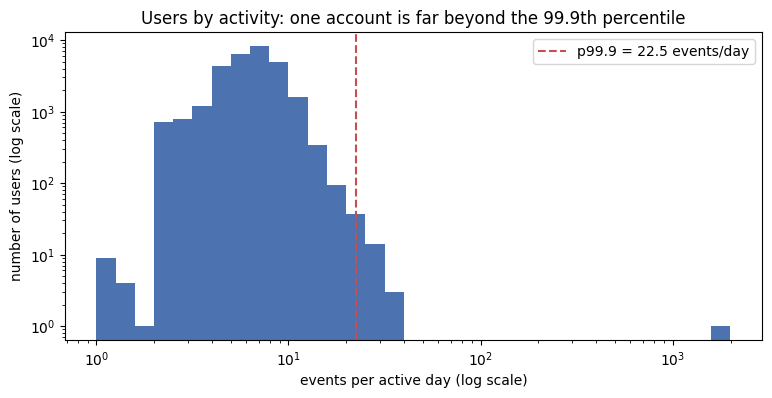

In [19]:
# ===== График распределения (считаем гистограмму в Spark, в pandas — только ~50 корзинок) =====
import matplotlib.pyplot as plt
import numpy as np

hist = (user_stats
        .withColumn("bin", F.floor(F.log10("events_per_day") * 10) / 10)   # корзинки шириной 0.1 по log10
        .groupBy("bin").count().orderBy("bin").toPandas())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(10 ** hist["bin"], hist["count"], width=10 ** (hist["bin"] + 0.1) - 10 ** hist["bin"],
       align="edge", color="#4C72B0")
ax.axvline(EPD_P999, color="#C44E52", linestyle="--", label=f"p99.9 = {EPD_P999:.1f} events/day")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("events per active day (log scale)")
ax.set_ylabel("number of users (log scale)")
ax.set_title("Users by activity: one account is far beyond the 99.9th percentile")
ax.legend()
plt.savefig(f"{RESULTS}/B_bot_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# ===== Помечаем ботов (не удаляем!) и собираем итоговый silver =====
bot_flags = bots.select("user_id").withColumn("is_bot", F.lit(True))

silver = (silver_base
          .join(F.broadcast(bot_flags), on="user_id", how="left")
          .withColumn("is_bot", F.coalesce(F.col("is_bot"), F.lit(False)))
          .cache())

n_bot_users = bots.count()
n_bot_events = silver.filter("is_bot").count()
bot_summary = pd.DataFrame([{
    "rule": "events_per_day > p99.9 AND n_events > p99.9 AND no cart/purchase activity",
    "p999_events_per_day": round(EPD_P999, 2), "p999_n_events": N_P999,
    "bot_users": n_bot_users, "bot_events": n_bot_events,
    "pct_of_silver_events": round(100 * n_bot_events / N_SILVER, 2)}])
bot_summary.to_csv(f"{RESULTS}/B_bot_summary.csv", index=False)
bot_summary.T

,0
rule,events_per_day > p99.9 AND n_events > p99.9 AN...
p999_events_per_day,22.5
p999_n_events,1044
bot_users,1
bot_events,106312
pct_of_silver_events,3.85


In [21]:
# Сколько event_type было "грязных", но исправилось нормализацией (а не попало в карантин)
n_fixed = deduped.filter(F.col("event_type") != F.lower(F.trim("event_type"))).count()
print("исправлено нормализацией event_type:", n_fixed)

исправлено нормализацией event_type: 28402


# Part A. Как сохранить Silver на диск

## A2.1. Подготовка

In [22]:
# ===== Part A2. Silver на диск =====
# Один раз сохраняем silver "как есть", без раскладки по папкам.
# Это (1) unpartitioned-версия для A3 и (2) общий источник, чтобы честно сравнить три способа записи.
SILVER_FLAT = f"{LAKE}/silver_flat"
silver.write.mode("overwrite").parquet(SILVER_FLAT)
silver_src = spark.read.parquet(SILVER_FLAT)

# Освобождаем память от промежуточных таблиц
for df_ in (deduped, checked, silver_base, user_stats, silver):
    df_.unpersist()
print("строк:", silver_src.count(), "| партиций при чтении:", silver_src.rdd.getNumPartitions())

строк: 2764395 | партиций при чтении: 16


In [23]:
def file_stats(path):
    """Считает parquet-файлы в папке (со всеми подпапками) и их размеры."""
    sizes, days = [], set()
    for root, _, files in os.walk(path):
        for f in files:
            if f.endswith(".parquet"):
                sizes.append(os.path.getsize(os.path.join(root, f)))
                days.add(os.path.basename(root))
    s = pd.Series(sizes) / 1024                                   # в КБ
    return {"n_files": len(sizes), "n_day_folders": len(days),
            "files_per_day": round(len(sizes) / max(1, len(days)), 1),
            "min_KB": round(s.min(), 1), "median_KB": round(s.median(), 1),
            "max_KB": round(s.max(), 1), "total_MB": round(s.sum() / 1024, 2)}

## A2.2. Своя стратегия 

Идея: самый большой день получает 4 файла, остальные дни — пропорционально своему размеру, но минимум 1. Тогда все файлы получаются примерно одинаковыми. Внутри дня строки делятся на «корзинки» по хэшу event_id, как раскладка карточек по последней цифре номера.

In [24]:
# Сколько строк в каждом дне и сколько файлов ему дать (1..4)
day_rows = silver_src.groupBy("event_date").count()
max_day = day_rows.agg(F.max("count")).first()[0]

day_files = (day_rows
             .withColumn("k", F.ceil(4 * F.col("count") / F.lit(max_day)).cast("int"))
             .withColumn("offset", F.sum("k").over(Window.orderBy("event_date")) - F.col("k")))
P = day_files.agg(F.sum("k")).first()[0]          # всего файлов будет примерно P
print("всего целевых файлов P =", P)

# Каждой строке: номер корзинки внутри дня (0..k-1) и уникальный номер файла part_id (0..P-1)
with_bucket = (silver_src
               .join(F.broadcast(day_files.select("event_date", "k", "offset")), "event_date")
               .withColumn("bucket", F.pmod(F.xxhash64("event_id"), F.col("k")))
               .withColumn("part_id", F.col("offset") + F.col("bucket")))

всего целевых файлов P = 198


## A2.3 Сравнения трех способов

In [25]:
PATHS = {
    "i_direct":       f"{LAKE}/silver_i_direct",
    "ii_repartition": f"{LAKE}/silver_ii_repartition",
    "iii_balanced":   f"{LAKE}/silver_iii_balanced",
}

def write_i():    # как есть: каждая задача пишет свой файл в КАЖДЫЙ день, который ей попался
    silver_src.write.mode("overwrite").partitionBy("event_date").parquet(PATHS["i_direct"])

def write_ii():   # все строки одного дня -> в одну задачу -> 1 файл на день
    (silver_src.repartition("event_date")
     .write.mode("overwrite").partitionBy("event_date").parquet(PATHS["ii_repartition"]))

def write_iii():  # каждая (день, корзинка) -> своя задача -> 1-4 файла на день примерно равного размера
    (with_bucket.repartitionByRange(P, "part_id")
     .drop("k", "offset", "bucket", "part_id")
     .write.mode("overwrite").partitionBy("event_date").parquet(PATHS["iii_balanced"]))

rows = []
for name, fn in [("i_direct", write_i), ("ii_repartition", write_ii), ("iii_balanced", write_iii)]:
    med, ts = bench(fn)
    rows.append({"strategy": name, "write_median_s": round(med, 2),
                 "runs_s": [round(t, 2) for t in ts], **file_stats(PATHS[name])})

a2 = pd.DataFrame(rows)
a2.to_csv(f"{RESULTS}/A2_write_strategies.csv", index=False)
a2

,strategy,write_median_s,runs_s,n_files,n_day_folders,files_per_day,min_KB,median_KB,max_KB,total_MB
0,i_direct,7.24,"[7.24, 8.79, 6.85]",960,60,16.0,53.8,150.1,215.3,145.65
1,ii_repartition,3.70,"[3.67, 3.83, 3.7]",60,60,1.0,1617.8,1762.1,2348.2,109.68
2,iii_balanced,8.56,"[8.56, 8.45, 11.12]",198,60,3.3,548.7,666.0,714.3,128.46


# Part A3 — partition pruning и pushdown

In [26]:
# ===== Part A3. "Выручка electronics-покупок с 2026-08-10 по 2026-08-16" на трёх видах хранения =====
import io, contextlib

D1, D2 = F.to_date(F.lit("2026-08-10")), F.to_date(F.lit("2026-08-16"))
electronics = products.filter(F.col("category") == "electronics").select("product_id")

def q_raw():
    df = spark.read.schema(event_schema).json(EVENTS)
    return (df.filter(F.lower(F.trim("event_type")) == "purchase")
              .withColumn("event_date", F.to_date(F.to_timestamp("event_ts", TS_FMT)))
              .filter(F.col("event_date").between(D1, D2))
              .join(F.broadcast(electronics), "product_id")
              .agg(F.round(F.sum(F.col("price") * F.col("quantity")), 2).alias("revenue")))

def q_parquet(path):
    df = spark.read.parquet(path)
    return (df.filter((F.col("event_type") == "purchase") & F.col("event_date").between(D1, D2))
              .join(F.broadcast(electronics), "product_id")
              .agg(F.round(F.sum(F.col("price") * F.col("quantity")), 2).alias("revenue")))

def plan_text(df):
    """Захватывает текст df.explain('formatted') в строку."""
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df.explain(mode="formatted")
    return buf.getvalue()

variants = {
    "raw_json":            q_raw,
    "parquet_unpartitioned": lambda: q_parquet(SILVER_FLAT),
    "parquet_partitioned":   lambda: q_parquet(PATHS["iii_balanced"]),
}

rows, plan_lines = [], []
for name, make_q in variants.items():
    med, ts = bench(lambda: force(make_q()))
    revenue = make_q().first()["revenue"]
    plan = plan_text(make_q())
    open(f"{RESULTS}/A3_plan_{name}.txt", "w").write(plan)          # полный план — в приложение отчёта
    for line in plan.splitlines():
        if any(k in line for k in ("PartitionFilters", "PushedFilters", "ReadSchema", "Location")):
            plan_lines.append({"variant": name, "plan_line": line.strip()[:300]})
    rows.append({"variant": name, "median_s": round(med, 3),
                 "runs_s": [round(t, 3) for t in ts], "revenue": revenue})

a3 = pd.DataFrame(rows)
a3.to_csv(f"{RESULTS}/A3_pruning_times.csv", index=False)
pd.DataFrame(plan_lines).to_csv(f"{RESULTS}/A3_plan_key_lines.csv", index=False)

assert a3.loc[1, "revenue"] == a3.loc[2, "revenue"], "две Parquet-версии должны давать одну выручку"
display(a3)
pd.set_option("display.max_colwidth", 300)
pd.DataFrame(plan_lines)

,variant,median_s,runs_s,revenue
0,raw_json,1.541,"[1.541, 1.541, 1.344]",428810.69
1,parquet_unpartitioned,0.436,"[0.442, 0.396, 0.436]",424863.19
2,parquet_partitioned,0.305,"[0.305, 0.279, 0.324]",424863.19


,variant,plan_line
0,raw_json,Location: InMemoryFileIndex [file:/C:/Users/Dana/Desktop/shopstream-spark/data/shopstream_medium_5820/events]
1,raw_json,PushedFilters: [IsNotNull(product_id)]
2,raw_json,"ReadSchema: struct<product_id:string,event_type:string,event_ts:string,price:double,quantity:bigint>"
3,raw_json,Location: InMemoryFileIndex [file:/C:/Users/Dana/Desktop/shopstream-spark/data/shopstream_medium_5820/products.csv]
4,raw_json,"PushedFilters: [IsNotNull(category), EqualTo(category,electronics), IsNotNull(product_id)]"
5,raw_json,"ReadSchema: struct<product_id:string,category:string>"
6,parquet_unpartitioned,Location: InMemoryFileIndex [file:/C:/Users/Dana/Desktop/shopstream-spark/data/shopstream_medium_5820/lake/silver_flat]
7,parquet_unpartitioned,"PushedFilters: [IsNotNull(event_type), IsNotNull(event_date), EqualTo(event_type,purchase), GreaterThanOrEqual(event_date,2026-08-10), LessThanOrEqual(event_date,2026-08-16), IsNotNull(product_id)]"
8,parquet_unpartitioned,"ReadSchema: struct<product_id:string,event_type:string,price:double,quantity:bigint,event_date:date>"
9,parquet_unpartitioned,Location: InMemoryFileIndex [file:/C:/Users/Dana/Desktop/shopstream-spark/data/shopstream_medium_5820/products.csv]


# Part C — аналитика

## C0. Подготовка

In [27]:
# ===== Part C. Аналитика (без ботов) =====
SILVER = PATHS["iii_balanced"]                 # партиционированный silver из A2
silver_all = spark.read.parquet(SILVER)
ev = silver_all.filter(~F.col("is_bot")).cache()
ev.createOrReplaceTempView("ev")               # чтобы к таблице можно было обращаться из SQL
print("событий без ботов:", ev.count())

def assert_same(df_api, df_sql, name):
    """Проверка: результаты DataFrame API и SQL совпадают строка в строку (в обе стороны).
    Дробные числа округляем до 6 знаков: сумма дробей может отличаться в 15-м знаке
    из-за порядка сложения, и это не ошибка."""
    cols = sorted(df_api.columns)
    def norm(df):
        return df.select([F.round(c, 6).alias(c) if t == "double" else F.col(c)
                          for c, t in df.select(cols).dtypes])
    a, b = norm(df_api), norm(df_sql)
    d1, d2 = a.exceptAll(b).count(), b.exceptAll(a).count()
    assert d1 == 0 and d2 == 0, f"{name}: различий {d1} / {d2}"
    print(f"{name}: DataFrame API == SQL ✓  ({a.count()} строк)")

событий без ботов: 2658083


## C1. Дневная подготовка

In [28]:
def c1_api(ev):
    is_type = lambda t: F.col("event_type") == t
    per_session = (ev.groupBy("event_date", "device", "session_id").agg(
        F.max(F.when(is_type("view"), 1).otherwise(0)).alias("has_view"),
        F.max(F.when(is_type("add_to_cart"), 1).otherwise(0)).alias("has_cart"),
        F.max(F.when(is_type("purchase"), 1).otherwise(0)).alias("has_purchase"),
        F.sum(F.when(is_type("purchase"), F.col("price") * F.col("quantity")).otherwise(0.0)).alias("gmv")))
    return (per_session.groupBy("event_date", "device").agg(
                F.sum("has_view").alias("view_sessions"),
                F.sum("has_cart").alias("cart_sessions"),
                F.sum("has_purchase").alias("purchase_sessions"),
                F.round(F.sum("gmv"), 2).alias("gmv"))
            .withColumn("view_to_cart", F.col("cart_sessions") / F.col("view_sessions"))
            .withColumn("cart_to_purchase", F.col("purchase_sessions") / F.col("cart_sessions")))

def c1_sql(ev):
    ev.createOrReplaceTempView("ev")
    return ev.sparkSession.sql("""
        WITH per_session AS (
            SELECT event_date, device, session_id,
                   MAX(CASE WHEN event_type = 'view'        THEN 1 ELSE 0 END) AS has_view,
                   MAX(CASE WHEN event_type = 'add_to_cart' THEN 1 ELSE 0 END) AS has_cart,
                   MAX(CASE WHEN event_type = 'purchase'    THEN 1 ELSE 0 END) AS has_purchase,
                   SUM(CASE WHEN event_type = 'purchase' THEN price * quantity ELSE 0.0 END) AS gmv
            FROM ev
            GROUP BY event_date, device, session_id)
        SELECT event_date, device,
               SUM(has_view)     AS view_sessions,
               SUM(has_cart)     AS cart_sessions,
               SUM(has_purchase) AS purchase_sessions,
               ROUND(SUM(gmv), 2) AS gmv,
               SUM(has_cart) / SUM(has_view)     AS view_to_cart,
               SUM(has_purchase) / SUM(has_cart) AS cart_to_purchase
        FROM per_session
        GROUP BY event_date, device""")

funnel = c1_api(ev)
assert_same(funnel, c1_sql(ev), "C1 funnel")
funnel_pd = funnel.orderBy("event_date", "device").toPandas()      # ~180 строк — можно в pandas
funnel_pd.to_csv(f"{RESULTS}/C1_funnel.csv", index=False)
funnel_pd.head(10)

C1 funnel: DataFrame API == SQL ✓  (180 строк)


,event_date,device,view_sessions,cart_sessions,purchase_sessions,gmv,view_to_cart,cart_to_purchase
0,2026-07-01,desktop,2188,850,380,56682.35,0.388483,0.447059
1,2026-07-01,mobile,3953,1546,700,92627.63,0.391095,0.452781
2,2026-07-01,tablet,952,367,157,19266.74,0.385504,0.427793
3,2026-07-02,desktop,2141,819,374,44527.38,0.382532,0.456654
4,2026-07-02,mobile,4003,1605,689,96286.25,0.400949,0.429283
5,2026-07-02,tablet,920,377,164,19255.27,0.409783,0.435013
6,2026-07-03,desktop,2131,859,396,49544.27,0.403097,0.461001
7,2026-07-03,mobile,4032,1605,664,91080.50,0.398065,0.413707
8,2026-07-03,tablet,938,368,172,17999.86,0.392324,0.467391
9,2026-07-04,desktop,2836,1107,467,60686.84,0.390339,0.421861


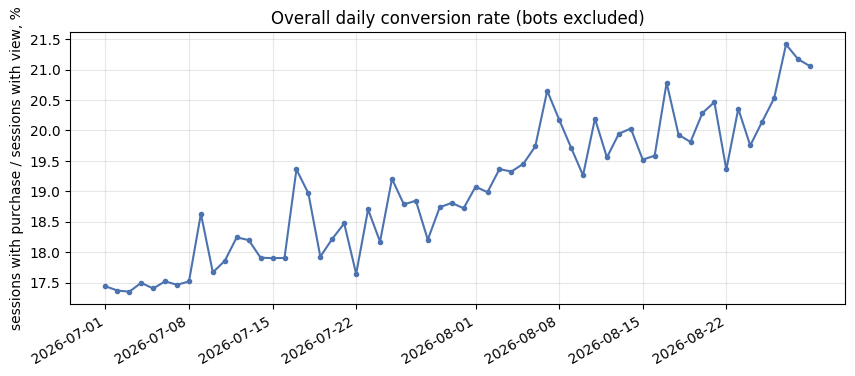

In [29]:
# График: общая дневная конверсия (все устройства вместе)
daily = funnel_pd.groupby("event_date")[["view_sessions", "cart_sessions", "purchase_sessions"]].sum()
daily["view_to_purchase"] = daily["purchase_sessions"] / daily["view_sessions"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, 100 * daily["view_to_purchase"], marker="o", markersize=3, color="#4C72B0")
ax.set_ylabel("sessions with purchase / sessions with view, %")
ax.set_title("Overall daily conversion rate (bots excluded)")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.savefig(f"{RESULTS}/C1_daily_conversion.png", dpi=150, bbox_inches="tight")
plt.show()

## C2. Пересборка сессий

In [30]:
def c2_api(ev):
    w = Window.partitionBy("user_id").orderBy("event_ts", "event_id")
    return (ev.select("event_id", "user_id", "session_id", "event_ts")
            .withColumn("prev_ts", F.lag("event_ts").over(w))
            .withColumn("new_sess", F.when(F.col("prev_ts").isNull()
                         | (F.col("event_ts").cast("long") - F.col("prev_ts").cast("long") > 1800), 1).otherwise(0))
            .withColumn("sess_no", F.sum("new_sess").over(w.rowsBetween(Window.unboundedPreceding, 0)))
            .withColumn("new_session_id", F.concat_ws("_", "user_id", F.col("sess_no").cast("string")))
            .select("event_id", "user_id", "session_id", "event_ts", "new_session_id"))

def c2_sql(ev):
    ev.createOrReplaceTempView("ev")
    return ev.sparkSession.sql("""
        WITH g AS (
            SELECT event_id, user_id, session_id, event_ts,
                   LAG(event_ts) OVER (PARTITION BY user_id ORDER BY event_ts, event_id) AS prev_ts
            FROM ev),
        f AS (
            SELECT *, CASE WHEN prev_ts IS NULL
                             OR unix_timestamp(event_ts) - unix_timestamp(prev_ts) > 1800
                           THEN 1 ELSE 0 END AS new_sess
            FROM g)
        SELECT event_id, user_id, session_id, event_ts,
               concat_ws('_', user_id, CAST(SUM(new_sess) OVER (
                   PARTITION BY user_id ORDER BY event_ts, event_id
                   ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS STRING)) AS new_session_id
        FROM f""")

sessd = c2_api(ev).cache()
assert_same(sessd, c2_sql(ev), "C2 sessionization")

C2 sessionization: DataFrame API == SQL ✓  (2658083 строк)


In [31]:
# Сравнение: старые сессии vs пересобранные
def session_summary(df, sess_col):
    s = df.groupBy(sess_col).agg(
        F.count("*").alias("n_events"),
        (F.max("event_ts").cast("long") - F.min("event_ts").cast("long")).alias("duration_s"))
    r = s.agg(F.count("*").alias("n_sessions"),
              F.percentile_approx("n_events", 0.5, 100000).alias("median_events"),
              F.percentile_approx("duration_s", 0.5, 100000).alias("median_duration_s")).first()
    return r.asDict()

orig_to_new = sessd.groupBy("session_id").agg(F.countDistinct("new_session_id").alias("n_new"))
new_to_orig = sessd.groupBy("new_session_id").agg(F.countDistinct("session_id").alias("n_orig"))

n_orig = orig_to_new.count()
n_split = orig_to_new.filter("n_new > 1").count()      # старая сессия разрезана на несколько
n_merged = (sessd.join(new_to_orig.filter("n_orig > 1"), "new_session_id")
                 .select("session_id").distinct().count())   # старые сессии, слитые с другими

c2 = pd.DataFrame([{"version": "original session_id", **session_summary(sessd, "session_id")},
                   {"version": "rebuilt (30-min gap)", **session_summary(sessd, "new_session_id")}])
c2["pct_original_split"]  = [round(100 * n_split / n_orig, 2), None]
c2["pct_original_merged"] = [round(100 * n_merged / n_orig, 2), None]
c2.to_csv(f"{RESULTS}/C2_sessionization.csv", index=False)
c2

,version,n_sessions,median_events,median_duration_s,pct_original_split,pct_original_merged
0,original session_id,454582,4,158,0.0,4.37
1,rebuilt (30-min gap),444399,5,163,NaN,NaN


In [32]:
# Конкретный пример расхождения: одна новая сессия, в которую слились несколько старых
example = (new_to_orig.filter("n_orig > 1").orderBy("new_session_id").limit(1))
(sessd.join(example, "new_session_id")
      .withColumn("gap_min", F.round((F.col("event_ts").cast("long")
                  - F.lag("event_ts").over(Window.orderBy("event_ts")).cast("long")) / 60, 1))
      .select("user_id", "session_id", "new_session_id", "event_ts", "gap_min")
      .orderBy("event_ts").show(40, truncate=False))

+--------+----------+--------------+-------------------+-------+
|user_id |session_id|new_session_id|event_ts           |gap_min|
+--------+----------+--------------+-------------------+-------+
|u_000014|s_00000087|u_000014_12   |2026-07-30 14:00:22|NULL   |
|u_000014|s_00000087|u_000014_12   |2026-07-30 14:00:31|0.2    |
|u_000014|s_00000087|u_000014_12   |2026-07-30 14:01:22|0.9    |
|u_000014|s_00000087|u_000014_12   |2026-07-30 14:01:52|0.5    |
|u_000014|s_00000087|u_000014_12   |2026-07-30 14:02:16|0.4    |
|u_000014|s_00000087|u_000014_12   |2026-07-30 14:03:59|1.7    |
|u_000014|s_00000087|u_000014_12   |2026-07-30 14:05:43|1.7    |
|u_000014|s_00000087|u_000014_12   |2026-07-30 14:07:02|1.3    |
|u_000014|s_00000087|u_000014_12   |2026-07-30 14:07:37|0.6    |
|u_000014|s_00000087|u_000014_12   |2026-07-30 14:08:13|0.6    |
|u_000014|s_00000087|u_000014_12   |2026-07-30 14:09:13|1.0    |
|u_000014|s_00000086|u_000014_12   |2026-07-30 14:23:47|14.6   |
|u_000014|s_00000086|u_00

## C3. Топ-5 товаров по категориям и неделям

In [33]:
cat = products.select("product_id", "category")

def c3_api(ev):
    rev = (ev.filter(F.col("event_type") == "purchase")
           .join(F.broadcast(cat), "product_id")
           .withColumn("week_start", F.to_date(F.date_trunc("week", "event_date")))   # понедельник ISO-недели
           .withColumn("iso_week", F.weekofyear("event_date"))
           .groupBy("category", "iso_week", "week_start", "product_id")
           .agg(F.round(F.sum(F.col("price") * F.col("quantity")), 2).alias("revenue")))
    w_cat = Window.partitionBy("category", "iso_week")
    return (rev.withColumn("rank", F.dense_rank().over(w_cat.orderBy(F.desc("revenue"))))
               .withColumn("category_week_revenue", F.sum("revenue").over(w_cat))
               .withColumn("share", F.col("revenue") / F.col("category_week_revenue"))
               .filter(F.col("rank") <= 5))

def c3_sql(ev):
    ev.createOrReplaceTempView("ev")
    cat.createOrReplaceTempView("cat")
    return ev.sparkSession.sql("""
        WITH rev AS (
            SELECT c.category, weekofyear(e.event_date) AS iso_week,
                   to_date(date_trunc('week', e.event_date)) AS week_start,
                   e.product_id, ROUND(SUM(e.price * e.quantity), 2) AS revenue
            FROM ev e JOIN cat c ON e.product_id = c.product_id
            WHERE e.event_type = 'purchase'
            GROUP BY c.category, weekofyear(e.event_date), to_date(date_trunc('week', e.event_date)), e.product_id),
        ranked AS (
            SELECT *,
                   DENSE_RANK() OVER (PARTITION BY category, iso_week ORDER BY revenue DESC) AS rank,
                   SUM(revenue) OVER (PARTITION BY category, iso_week) AS category_week_revenue
            FROM rev)
        SELECT *, revenue / category_week_revenue AS share
        FROM ranked WHERE rank <= 5""")

top = c3_api(ev)
assert_same(top, c3_sql(ev), "C3 top products")
top_pd = top.orderBy("category", "iso_week", "rank").toPandas()
top_pd.to_csv(f"{RESULTS}/C3_top_products.csv", index=False)
top_pd.head(15)

C3 top products: DataFrame API == SQL ✓  (450 строк)


,category,iso_week,week_start,product_id,revenue,rank,category_week_revenue,share
0,auto,27,2026-06-29,p_01970,96882.12,1,153155.95,0.632572
1,auto,27,2026-06-29,p_00702,11488.68,2,153155.95,0.075013
2,auto,27,2026-06-29,p_02135,2768.06,3,153155.95,0.018073
3,auto,27,2026-06-29,p_02172,2311.13,4,153155.95,0.015090
4,auto,27,2026-06-29,p_03010,1744.72,5,153155.95,0.011392
5,auto,28,2026-07-06,p_01970,132391.20,1,214583.46,0.616968
6,auto,28,2026-07-06,p_00702,19369.38,2,214583.46,0.090265
7,auto,28,2026-07-06,p_03010,5396.90,3,214583.46,0.025151
8,auto,28,2026-07-06,p_02135,3511.83,4,214583.46,0.016366
9,auto,28,2026-07-06,p_03040,2434.91,5,214583.46,0.011347


## C4. Липкость: DAU / WAU

In [34]:
def c4_api(ev):
    ua = ev.select("user_id", "event_date").distinct()             # кто в какой день был активен
    dau = ua.groupBy("event_date").agg(F.count("*").alias("dau"))
    wau = (ua.withColumn("day", F.explode(F.sequence("event_date", F.date_add("event_date", 6))))
             .groupBy("day").agg(F.countDistinct("user_id").alias("wau"))
             .withColumnRenamed("day", "event_date"))
    return (dau.join(wau, "event_date")                              # inner join: только дни с данными
               .withColumn("dau_wau", F.col("dau") / F.col("wau")))

def c4_sql(ev):
    ev.createOrReplaceTempView("ev")
    return ev.sparkSession.sql("""
        WITH ua AS (SELECT DISTINCT user_id, event_date FROM ev),
        dau AS (SELECT event_date, COUNT(*) AS dau FROM ua GROUP BY event_date),
        wau AS (SELECT d AS event_date, COUNT(DISTINCT user_id) AS wau
                FROM ua LATERAL VIEW explode(sequence(event_date, date_add(event_date, 6))) t AS d
                GROUP BY d)
        SELECT dau.event_date, dau, wau, dau / wau AS dau_wau
        FROM dau JOIN wau ON dau.event_date = wau.event_date""")

stick = c4_api(ev)
assert_same(stick, c4_sql(ev), "C4 stickiness")
stick_pd = stick.orderBy("event_date").toPandas()
stick_pd.to_csv(f"{RESULTS}/C4_stickiness.csv", index=False)
stick_pd.head(10)

C4 stickiness: DataFrame API == SQL ✓  (60 строк)


,event_date,dau,wau,dau_wau
0,2026-07-01,5906,5906,1.000000
1,2026-07-02,5903,10082,0.585499
2,2026-07-03,5872,13164,0.446065
3,2026-07-04,7515,16356,0.459464
4,2026-07-05,7559,18677,0.404722
5,2026-07-06,5910,19997,0.295544
6,2026-07-07,6012,21135,0.284457
7,2026-07-08,6002,21135,0.283984
8,2026-07-09,5880,21076,0.278990
9,2026-07-10,5838,20992,0.278106


In [35]:
# Проверка "в лоб" на 3 днях: прямо считаем уникальных пользователей за 7 дней
import datetime as dt
days = [stick_pd["event_date"].iloc[i] for i in (0, len(stick_pd) // 2, -1)]   # первый, средний, последний
for d in days:
    brute = (ev.filter(F.col("event_date").between(d - dt.timedelta(days=6), d))
               .select("user_id").distinct().count())
    ours = int(stick_pd.loc[stick_pd["event_date"] == d, "wau"].iloc[0])
    assert brute == ours, f"{d}: {brute} != {ours}"
    print(f"{d}: brute force {brute} == distributed {ours} ✓")

2026-07-01: brute force 5906 == distributed 5906 ✓


2026-07-31: brute force 18675 == distributed 18675 ✓


2026-08-29: brute force 15441 == distributed 15441 ✓


# Part D — joins, перекос и AQE

## D0. Подготовка

In [36]:
# ===== Part D. Joins, skew и AQE (боты ОСТАЮТСЯ в данных) =====
from contextlib import contextmanager

silver_d = spark.read.parquet(SILVER)                         # с ботами
users_d  = users                                              # users.csv
N_SILVER_D = silver_d.count()

@contextmanager
def spark_conf(settings):
    """Временно меняет настройки Spark и потом возвращает старые."""
    old = {k: spark.conf.get(k, None) for k in settings}
    for k, v in settings.items():
        spark.conf.set(k, v)
    try:
        yield
    finally:
        for k, v in old.items():
            if v is None: spark.conf.unset(k)
            else: spark.conf.set(k, v)

def checksum(df):
    """Контрольная сумма, не зависящая от порядка строк: сумма хэшей всех колонок."""
    cols = sorted(df.columns)
    return df.agg(F.count("*").alias("rows"),
                  F.sum(F.xxhash64(*cols).cast("decimal(38,0)")).alias("checksum"))

# Во всей Part D запрещаем автоматический broadcast: users считается "большой" таблицей
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")

## D1. Диагностика перекоса

In [37]:
# Топ-10 ключей по числу строк
key_counts = silver_d.groupBy("user_id").count().cache()
top10 = key_counts.orderBy(F.desc("count")).limit(10).toPandas()
median_key = key_counts.agg(F.percentile_approx("count", 0.5)).first()[0]
top10["x_median_key"] = (top10["count"] / median_key).round(1)
top10.to_csv(f"{RESULTS}/D1_top10_keys.csv", index=False)
print("медиана строк на пользователя:", median_key)
top10

медиана строк на пользователя: 60


,user_id,count,x_median_key
0,u_000000,106312,1771.9
1,u_025828,1805,30.1
2,u_015380,1640,27.3
3,u_023211,1605,26.8
4,u_020785,1522,25.4
5,u_008424,1466,24.4
6,u_019938,1454,24.2
7,u_021862,1453,24.2
8,u_000929,1420,23.7
9,u_013502,1361,22.7


{'partitions': 200, 'max_rows': 119530, 'median_rows': 13202.5, 'min_rows': 8679, 'max_to_median': 9.1}


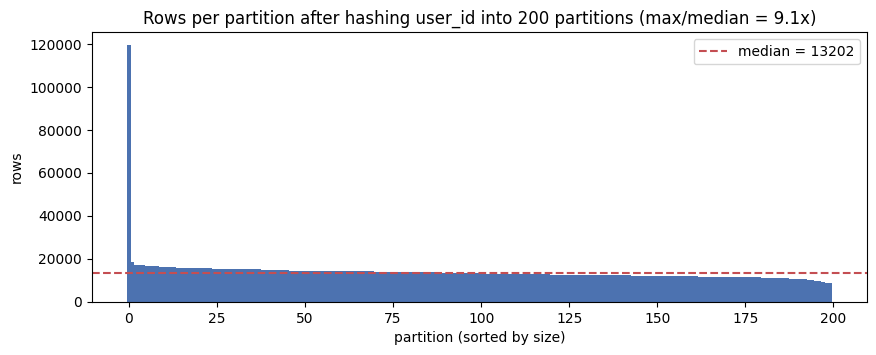

In [38]:
# Как строки разложатся по 200 "коробкам" при хэшировании по user_id
part_rows = (silver_d.repartition(200, "user_id")
             .groupBy(F.spark_partition_id().alias("partition")).count()
             .toPandas().sort_values("count", ascending=False))
d1 = {"partitions": len(part_rows),
      "max_rows": int(part_rows["count"].max()),
      "median_rows": float(part_rows["count"].median()),
      "min_rows": int(part_rows["count"].min())}
d1["max_to_median"] = round(d1["max_rows"] / d1["median_rows"], 1)
pd.DataFrame([d1]).to_csv(f"{RESULTS}/D1_partition_skew.csv", index=False)
print(d1)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(part_rows)), part_rows["count"].values, color="#4C72B0", width=1.0)
ax.axhline(d1["median_rows"], color="#C44E52", linestyle="--", label=f"median = {d1['median_rows']:.0f}")
ax.set_xlabel("partition (sorted by size)"); ax.set_ylabel("rows")
ax.set_title(f"Rows per partition after hashing user_id into 200 partitions (max/median = {d1['max_to_median']}x)")
ax.legend()
plt.savefig(f"{RESULTS}/D1_partition_rows.png", dpi=150, bbox_inches="tight")
plt.show()

In [39]:
# Для скриншота: sort-merge join без AQE, подписанный в Spark UI
spark.sparkContext.setJobDescription("D1: sort-merge join, AQE off (for screenshot)")
with spark_conf({"spark.sql.adaptive.enabled": "false"}):
    force(silver_d.join(users_d, "user_id"))
spark.sparkContext.setJobDescription(None)

In [40]:
def join_plain():     return silver_d.join(users_d, "user_id")
def join_broadcast(): return silver_d.join(F.broadcast(users_d), "user_id")

AQE_OFF = {"spark.sql.adaptive.enabled": "false"}

def run_with_final_plan(df):
    """Выполняет checksum(df) и возвращает (результат, ФИНАЛЬНЫЙ план).
    Важно: collect() вызывается у самого chk — только тогда AQE строит финальный план
    (first() создал бы новый запрос, и мы бы увидели план "до выполнения")."""
    chk = checksum(df)
    res = chk.collect()[0]
    return res, plan_text(chk)

In [41]:
# AQE считает партицию перекошенной, только если она ОДНОВРЕМЕННО:
#   > skewedPartitionFactor × медиана партиций   И   > skewedPartitionThresholdInBytes.
# По умолчанию порог 256 МБ — на ноутбуке недостижим. Ищем самый большой порог, при котором срабатывает.
def aqe_skew_settings(factor, threshold_kb):
    return {
        "spark.sql.adaptive.enabled": "true",
        "spark.sql.adaptive.skewJoin.enabled": "true",
        "spark.sql.adaptive.skewJoin.skewedPartitionFactor": str(factor),
        "spark.sql.adaptive.skewJoin.skewedPartitionThresholdInBytes": f"{threshold_kb}KB",
        # на куски какого размера резать перекошенную партицию (должно быть меньше порога)
        "spark.sql.adaptive.advisoryPartitionSizeInBytes": f"{max(8, threshold_kb // 4)}KB",
    }

calibration, AQE_SKEW = [], None
for factor in (3, 2):
    for thr_kb in (1024, 512, 256, 128, 64, 32, 16):
        settings = aqe_skew_settings(factor, thr_kb)
        with spark_conf(settings):
            _, plan = run_with_final_plan(join_plain())
        triggered = "skew=true" in plan
        calibration.append({"factor": factor, "threshold_KB": thr_kb,
                            "final_plan": "isFinalPlan=true" in plan, "skew_triggered": triggered})
        print(f"factor={factor}, threshold={thr_kb:>4} KB -> skew join: {triggered}")
        if triggered:
            AQE_SKEW = settings
            break
    if AQE_SKEW:
        break

pd.DataFrame(calibration).to_csv(f"{RESULTS}/D2_aqe_skew_calibration.csv", index=False)
assert AQE_SKEW is not None, "AQE skew join не сработал ни при одном пороге — пришли вывод ячейки"
print("\nВыбранные настройки для (c):")
AQE_SKEW

factor=3, threshold=1024 KB -> skew join: True

Выбранные настройки для (c):


{'spark.sql.adaptive.enabled': 'true',
 'spark.sql.adaptive.skewJoin.enabled': 'true',
 'spark.sql.adaptive.skewJoin.skewedPartitionFactor': '3',
 'spark.sql.adaptive.skewJoin.skewedPartitionThresholdInBytes': '1024KB',
 'spark.sql.adaptive.advisoryPartitionSizeInBytes': '256KB'}

In [42]:
# Горячие ключи находим ПРОГРАММНО: ключ "горячий", если он один больше средней партиции.
avg_partition_rows = N_SILVER_D / 200
HOT_KEYS = [r["user_id"] for r in key_counts.filter(F.col("count") > avg_partition_rows).collect()]
print(f"средняя партиция = {avg_partition_rows:.0f} строк | горячие ключи: {HOT_KEYS}")

def join_salted(N):
    is_hot = F.col("user_id").isin(HOT_KEYS)
    left = silver_d.withColumn(
        "salt", F.when(is_hot, F.pmod(F.xxhash64("event_id"), F.lit(N))).otherwise(F.lit(0)).cast("int"))
    users_hot = (users_d.filter(F.col("user_id").isin(HOT_KEYS))
                 .withColumn("salt", F.explode(F.sequence(F.lit(0), F.lit(N - 1)))))
    users_cold = users_d.filter(~F.col("user_id").isin(HOT_KEYS)).withColumn("salt", F.lit(0))
    right = users_hot.unionByName(users_cold)
    return left.join(right, ["user_id", "salt"]).drop("salt")

средняя партиция = 13822 строк | горячие ключи: ['u_000000']


In [43]:
experiments = [
    ("a) broadcast hash join",            AQE_OFF,  join_broadcast),
    ("b) sort-merge, AQE off",            AQE_OFF,  join_plain),
    ("c) sort-merge, AQE skew join",      AQE_SKEW, join_plain),
    ("d) sort-merge, AQE off, salt N=4",  AQE_OFF,  lambda: join_salted(4)),
    ("d) sort-merge, AQE off, salt N=16", AQE_OFF,  lambda: join_salted(16)),
    ("d) sort-merge, AQE off, salt N=64", AQE_OFF,  lambda: join_salted(64)),
]

rows = []
for i, (name, settings, make_join) in enumerate(experiments):
    with spark_conf(settings):
        med, ts = bench(lambda: force(make_join()))
        res, plan = run_with_final_plan(make_join())        # доказательство из финального плана
    open(f"{RESULTS}/D2_plan_{i}.txt", "w").write(f"-- {name}\n{plan}")
    rows.append({"strategy": name, "median_s": round(med, 2), "runs_s": [round(t, 2) for t in ts],
                 "join_type": "BroadcastHashJoin" if "BroadcastHashJoin" in plan else "SortMergeJoin",
                 "aqe_skew_triggered": "skew=true" in plan,
                 "rows": res["rows"], "checksum": str(res["checksum"])})

d2 = pd.DataFrame(rows)
d2.to_csv(f"{RESULTS}/D2_join_matrix.csv", index=False)

assert d2.loc[2, "aqe_skew_triggered"], "в (c) AQE skew join не сработал"
assert d2["checksum"].nunique() == 1 and d2["rows"].nunique() == 1, "стратегии дали разные результаты!"
d2

,strategy,median_s,runs_s,join_type,aqe_skew_triggered,rows,checksum
0,a) broadcast hash join,0.67,"[0.75, 0.65, 0.67]",BroadcastHashJoin,False,2764395,-4180944823663921388348
1,"b) sort-merge, AQE off",5.13,"[5.13, 4.9, 5.36]",SortMergeJoin,False,2764395,-4180944823663921388348
2,"c) sort-merge, AQE skew join",6.88,"[6.23, 6.88, 7.01]",SortMergeJoin,True,2764395,-4180944823663921388348
3,"d) sort-merge, AQE off, salt N=4",5.16,"[5.5, 5.16, 5.08]",SortMergeJoin,False,2764395,-4180944823663921388348
4,"d) sort-merge, AQE off, salt N=16",5.11,"[5.06, 5.31, 5.11]",SortMergeJoin,False,2764395,-4180944823663921388348
5,"d) sort-merge, AQE off, salt N=64",5.20,"[5.2, 5.33, 5.1]",SortMergeJoin,False,2764395,-4180944823663921388348


In [44]:
# Покажем строки финального плана (c), где видно, что партиция разрезана
plan_c = open(f"{RESULTS}/D2_plan_2.txt").read()
for line in plan_c.splitlines():
    if any(k in line for k in ("SortMergeJoin", "AQEShuffleRead", "isFinalPlan", "skew")):
        print(line.strip()[:200])

-- c) sort-merge, AQE skew join
+- * SortMergeJoin(skew=true) Inner (14)
:  +- AQEShuffleRead (6)
+- AQEShuffleRead (12)
+- SortMergeJoin Inner (26)
(6) AQEShuffleRead
Arguments: coalesced and skewed
(12) AQEShuffleRead
(14) SortMergeJoin(skew=true) [codegen id : 5]
(26) SortMergeJoin
Arguments: isFinalPlan=true


# Part E — партиции, кэш и масштабирование

## E0. Подготовка

In [45]:
# ===== Part E. Партиции, кэш и масштабирование =====
import itertools
import numpy as np

# В Part D мы отключали автоматический broadcast — возвращаем значение по умолчанию
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold")

def run_W(sp, use_cache=False):
    """Workload W = C1 + C3 + C4 на партиционированном silver (без ботов)."""
    global cat                                             # c3_api берёт справочник категорий из cat
    cat = sp.read.csv(f"{DATA}/products.csv", header=True).select("product_id", "category")
    ev_w = sp.read.parquet(SILVER).filter(~F.col("is_bot"))
    if use_cache:
        ev_w = ev_w.cache()        # заполнится во время C1, а C3 и C4 прочитают уже из памяти
    for query in (c1_api, c3_api, c4_api):
        force(query(ev_w))

def time_W(sp, use_cache=False, runs=3):
    """Прогрев + 3 замера. Возвращает медиану, IQR и все времена."""
    run_W(sp, use_cache)                                   # прогрев, не учитываем
    ts = []
    for _ in range(runs):
        sp.catalog.clearCache()
        t0 = time.perf_counter()
        run_W(sp, use_cache)
        ts.append(time.perf_counter() - t0)
    q25, q75 = np.percentile(ts, [25, 75])
    return statistics.median(ts), q75 - q25, ts

def make_spark(master):
    return (SparkSession.builder
            .master(master)
            .appName("ShopStream-A2")
            .config("spark.sql.session.timeZone", "UTC")
            .config("spark.local.dir", os.path.abspath("spark_tmp"))
            .config("spark.ui.port", "4040")
            .getOrCreate())

## E1. Сетка: партиции × AQE coalescing × кэш

In [46]:
grid_rows = []
for n_part, coalesce, use_cache in itertools.product([8, 32, 128, 512], [True, False], [True, False]):
    settings = {
        "spark.sql.adaptive.enabled": "true",
        "spark.sql.shuffle.partitions": str(n_part),
        "spark.sql.adaptive.coalescePartitions.enabled": str(coalesce).lower(),
    }
    with spark_conf(settings):
        med, iqr, ts = time_W(spark, use_cache)
    grid_rows.append({"shuffle_partitions": n_part, "aqe_coalesce": coalesce, "cache": use_cache,
                      "median_s": round(med, 2), "iqr_s": round(iqr, 2), "runs_s": [round(t, 2) for t in ts]})
    print(f"partitions={n_part:>3} coalesce={str(coalesce):5} cache={str(use_cache):5} -> {med:.2f} s (IQR {iqr:.2f})")

grid = pd.DataFrame(grid_rows)
grid.to_csv(f"{RESULTS}/E1_grid.csv", index=False)

partitions=  8 coalesce=True  cache=True  -> 5.58 s (IQR 0.42)


partitions=  8 coalesce=True  cache=False -> 3.80 s (IQR 0.58)


partitions=  8 coalesce=False cache=True  -> 5.67 s (IQR 0.27)


partitions=  8 coalesce=False cache=False -> 3.35 s (IQR 0.25)


partitions= 32 coalesce=True  cache=True  -> 7.70 s (IQR 0.43)


...

partitions=128 coalesce=False cache=False -> 52.68 s (IQR 0.39)


partitions=512 coalesce=True  cache=True  -> 6.40 s (IQR 0.32)


partitions=512 coalesce=True  cache=False -> 3.15 s (IQR 0.26)


partitions=512 coalesce=False cache=True  -> 45.20 s (IQR 2.64)


partitions=512 coalesce=False cache=False -> 38.32 s (IQR 0.21)


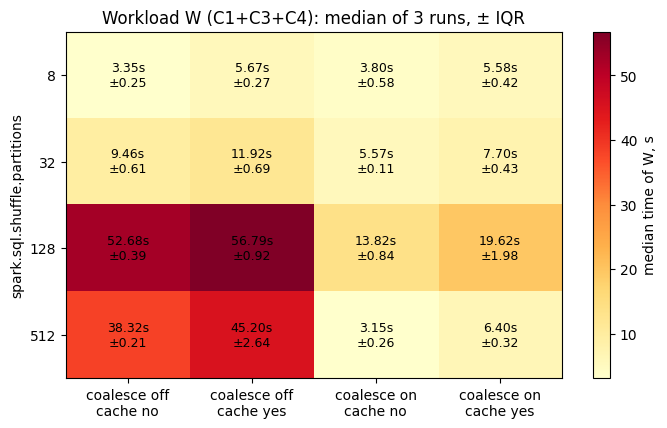

Лучшая конфигурация: {'shuffle_partitions': 512, 'aqe_coalesce': True, 'cache': False, 'median_s': 3.15}


In [47]:
# Тепловая карта: строки — число партиций, столбцы — комбинации AQE coalescing × cache
grid["config"] = grid.apply(lambda r: f"coalesce {'on' if r.aqe_coalesce else 'off'}\ncache {'yes' if r.cache else 'no'}", axis=1)
heat = grid.pivot(index="shuffle_partitions", columns="config", values="median_s")
iqr_t = grid.pivot(index="shuffle_partitions", columns="config", values="iqr_s")

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(heat.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.set_ylabel("spark.sql.shuffle.partitions")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.2f}s\n±{iqr_t.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="median time of W, s")
ax.set_title("Workload W (C1+C3+C4): median of 3 runs, ± IQR")
plt.savefig(f"{RESULTS}/E1_grid_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

best = grid.loc[grid["median_s"].idxmin()]
print("Лучшая конфигурация:", best[["shuffle_partitions", "aqe_coalesce", "cache", "median_s"]].to_dict())

## E2. Масштабирование по ядрам и закон Амдала

In [48]:
BEST_SETTINGS = {
    "spark.sql.adaptive.enabled": "true",
    "spark.sql.shuffle.partitions": str(int(best["shuffle_partitions"])),
    "spark.sql.adaptive.coalescePartitions.enabled": str(bool(best["aqe_coalesce"])).lower(),
}
BEST_CACHE = bool(best["cache"])

scal_rows = []
for master in ["local[1]", "local[2]", "local[4]", "local[8]", "local[*]"]:
    spark.stop()                                   # новая SparkSession на каждое число ядер
    spark = make_spark(master)
    spark.sparkContext.setLogLevel("WARN")
    cores = spark.sparkContext.defaultParallelism
    with spark_conf(BEST_SETTINGS):
        med, iqr, ts = time_W(spark, BEST_CACHE)
    scal_rows.append({"master": master, "cores": cores, "median_s": round(med, 2),
                      "iqr_s": round(iqr, 2), "runs_s": [round(t, 2) for t in ts]})
    print(f"{master:9} ({cores:>2} cores) -> {med:.2f} s")

scal = pd.DataFrame(scal_rows)

local[1]  ( 1 cores) -> 8.57 s


local[2]  ( 2 cores) -> 5.46 s


local[4]  ( 4 cores) -> 3.55 s


local[8]  ( 8 cores) -> 2.83 s


local[*]  (16 cores) -> 2.91 s


последовательная доля s = 0.257  ->  максимально возможное ускорение 1/s = 3.9x


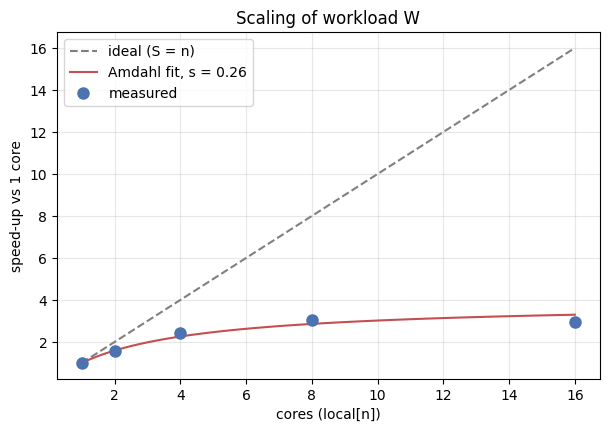

,master,cores,median_s,iqr_s,runs_s,speedup,amdahl_fit
0,local[1],1,8.57,0.13,"[8.57, 8.47, 8.72]",1.00,1.00
1,local[2],2,5.46,0.16,"[5.46, 5.61, 5.29]",1.57,1.59
2,local[4],4,3.55,0.02,"[3.54, 3.57, 3.55]",2.41,2.26
3,local[8],8,2.83,0.09,"[2.92, 2.73, 2.83]",3.03,2.86
4,local[*],16,2.91,0.08,"[3.05, 2.91, 2.88]",2.95,3.30


In [49]:
# Закон Амдала: S(n) = 1 / (s + (1 - s) / n), s — доля работы, которая не распараллеливается.
# Перепишем: 1/S - 1/n = s · (1 - 1/n)  ->  прямая через ноль, s находим методом наименьших квадратов.
T1 = scal.loc[scal["cores"] == 1, "median_s"].iloc[0]
scal["speedup"] = (T1 / scal["median_s"]).round(2)
x = 1 - 1 / scal["cores"]
y = 1 / scal["speedup"] - 1 / scal["cores"]
s_serial = float((x * y).sum() / (x * x).sum())
scal["amdahl_fit"] = (1 / (s_serial + (1 - s_serial) / scal["cores"])).round(2)
scal.to_csv(f"{RESULTS}/E2_scaling.csv", index=False)
print(f"последовательная доля s = {s_serial:.3f}  ->  максимально возможное ускорение 1/s = {1 / s_serial:.1f}x")

n_grid = np.linspace(1, scal["cores"].max(), 100)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(n_grid, n_grid, "--", color="gray", label="ideal (S = n)")
ax.plot(n_grid, 1 / (s_serial + (1 - s_serial) / n_grid), color="#C44E52", label=f"Amdahl fit, s = {s_serial:.2f}")
ax.plot(scal["cores"], scal["speedup"], "o", color="#4C72B0", markersize=8, label="measured")
ax.set_xlabel("cores (local[n])"); ax.set_ylabel("speed-up vs 1 core")
ax.set_title("Scaling of workload W")
ax.legend(); ax.grid(alpha=0.3)
plt.savefig(f"{RESULTS}/E2_scaling_amdahl.png", dpi=150, bbox_inches="tight")
plt.show()
scal

In [50]:
# Возвращаем обычную сессию со всеми ядрами (на случай, если дальше будут ячейки)
spark.stop()
spark = make_spark("local[*]")
spark.sparkContext.setLogLevel("WARN")

In [51]:
# ===== E1b. Проверяем: медленно ли из-за bypass-merge shuffle writer (файл на каждую партицию)? =====
# Отключаем bypass (порог 1 вместо 200) — это настройка ядра Spark, нужна новая сессия
spark.stop()
spark = (SparkSession.builder.master("local[*]").appName("ShopStream-A2")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.local.dir", os.path.abspath("spark_tmp"))
         .config("spark.shuffle.sort.bypassMergeThreshold", "1")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")

rows = []
for n_part in (32, 128):
    with spark_conf({"spark.sql.adaptive.enabled": "true",
                     "spark.sql.shuffle.partitions": str(n_part),
                     "spark.sql.adaptive.coalescePartitions.enabled": "false"}):
        med, iqr, ts = time_W(spark, use_cache=False)
    before = grid.query("shuffle_partitions == @n_part and not aqe_coalesce and not cache")["median_s"].iloc[0]
    rows.append({"shuffle_partitions": n_part, "bypass_on_s (grid)": before, "bypass_off_s": round(med, 2)})

bypass_check = pd.DataFrame(rows)
bypass_check.to_csv(f"{RESULTS}/E1b_bypass_check.csv", index=False)

spark.stop()
spark = make_spark("local[*]")          # возвращаем обычную сессию
spark.sparkContext.setLogLevel("WARN")
bypass_check

,shuffle_partitions,bypass_on_s (grid),bypass_off_s
0,32,9.46,3.57
1,128,52.68,8.57
